In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("vacant_posts_2026-02-07.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (31, 7)


,Sl. No.,Post Name,Post ID,Designation,Level,Office Name,Division
0,1,Abhaipur BO-ABPM-UR,30357210,ABPM,NaN,Abhaipur BO,Fatehpur Division
1,2,Akbarpur Churai BO-BPM-UR,30350278,BPM,NaN,Akbarpur Churai BO,Fatehpur Division
2,3,Allipur BO-BPM-UR,30350327,BPM,NaN,Allipur BO,Fatehpur Division
3,4,Amilihapal BO-ABPM-OBC,30362623,ABPM,NaN,Amilihapal BO,Fatehpur Division
4,5,Andipur BO-ABPM-UR,30639378,ABPM,NaN,Andipur BO,Fatehpur Division


In [2]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Sl. No.         0
Post Name       0
Post ID         0
Designation     0
Level          31
Office Name     0
Division        0
dtype: int64


In [3]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [4]:
print("Unique values in Level column:")
print(df["Level"].unique())

print("\nMissing values in Level:")
print(df["Level"].isnull().sum())

Unique values in Level column:
[nan]

Missing values in Level:
31


In [5]:
df = df.drop(columns=["Level"])

print("Dataset shape after removing empty column:", df.shape)
print("\nRemaining columns:")
print(df.columns.tolist())

Dataset shape after removing empty column: (31, 6)

Remaining columns:
['Sl. No.', 'Post Name', 'Post ID', 'Designation', 'Office Name', 'Division']


In [6]:
df = df.drop(columns=["Level"])

print("Dataset shape after removing empty column:", df.shape)
print("\nRemaining columns:")
print(df.columns.tolist())

KeyError: "['Level'] not found in axis"

In [7]:
print("Current columns:", df.columns.tolist())

if "Level" in df.columns:
    df = df.drop(columns=["Level"])
    print("Level column removed.")
else:
    print("Level column is already removed.")

print("Dataset shape:", df.shape)

Current columns: ['Sl. No.', 'Post Name', 'Post ID', 'Designation', 'Office Name', 'Division']
Level column is already removed.
Dataset shape: (31, 6)


In [8]:
text_columns = df.select_dtypes(include="object").columns

for col in text_columns:
    df[col] = df[col].str.strip()

print("Text cleaning completed!")
print("Columns cleaned:", text_columns.tolist())

Text cleaning completed!
Columns cleaned: ['Post Name', 'Designation', 'Office Name', 'Division']


/tmp/ipykernel_50110/672993141.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df.select_dtypes(include="object").columns


In [9]:
df.describe(include="all")

,Sl. No.,Post Name,Post ID,Designation,Office Name,Division
count,31.000000,31,3.100000e+01,31,31,31
unique,NaN,31,NaN,3,30,1
top,NaN,Abhaipur BO-ABPM-UR,NaN,ABPM,Datauli BO,Fatehpur Division
freq,NaN,1,NaN,18,2,31
mean,16.000000,NaN,3.293637e+07,NaN,NaN,NaN
std,9.092121,NaN,9.921115e+06,NaN,NaN,NaN
min,1.000000,NaN,3.035028e+07,NaN,NaN,NaN
25%,8.500000,NaN,3.035051e+07,NaN,NaN,NaN
50%,16.000000,NaN,3.035712e+07,NaN,NaN,NaN
75%,23.500000,NaN,3.035998e+07,NaN,NaN,NaN


In [10]:
print("Designation counts:")
print(df["Designation"].value_counts())

print("\nOffice-wise posts:")
print(df["Office Name"].value_counts())

print("\nDivision-wise posts:")
print(df["Division"].value_counts())

Designation counts:
Designation
ABPM        18
BPM         12
Daksevak     1
Name: count, dtype: int64

Office-wise posts:
Office Name
Datauli BO                 2
Abhaipur BO                1
Akbarpur Churai BO         1
Allipur BO                 1
Amilihapal BO              1
Andipur BO                 1
Arhawal BO                 1
Aung BO                    1
Baraipur BO                1
Bhakharana BO              1
Chandapur BO               1
Deolan BO                  1
Gauri BO                   1
Hardon BO                  1
Jahangirnagar Gahura BO    1
Jairampur BO               1
Korra Kanak BO             1
Kot BO                     1
Kotiya BO                  1
Lalauli SO                 1
Lamehata BO                1
MPGaunti BO                1
Shah BO                    1
Sithaura BO                1
Sothrapur BO               1
Sultanpurghosh BO          1
Tapani BO                  1
Tikar BO                   1
Ukathu BO                  1
Vijaeepur BO            

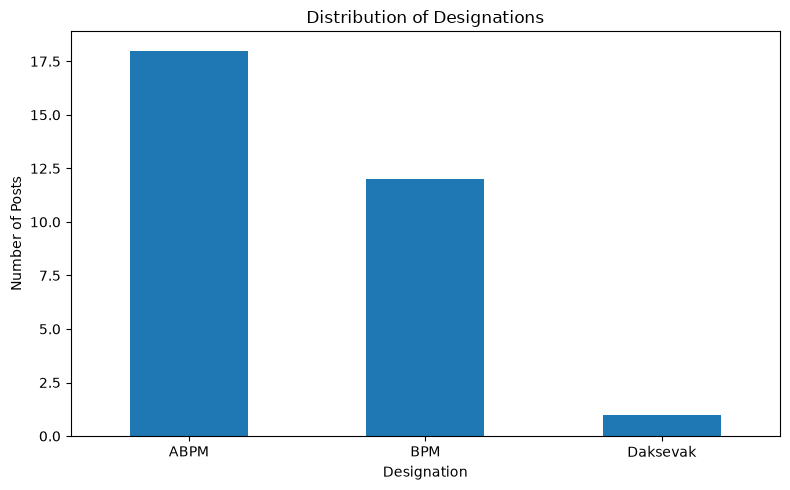

In [11]:
df["Designation"].value_counts().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Distribution of Designations")
plt.xlabel("Designation")
plt.ylabel("Number of Posts")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

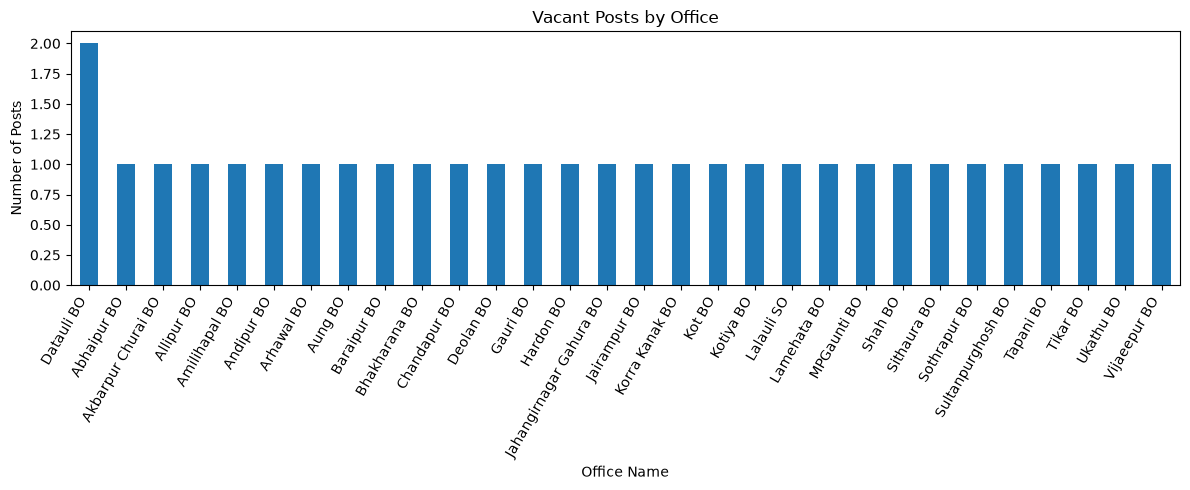

In [12]:
df["Office Name"].value_counts().plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Vacant Posts by Office")
plt.xlabel("Office Name")
plt.ylabel("Number of Posts")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

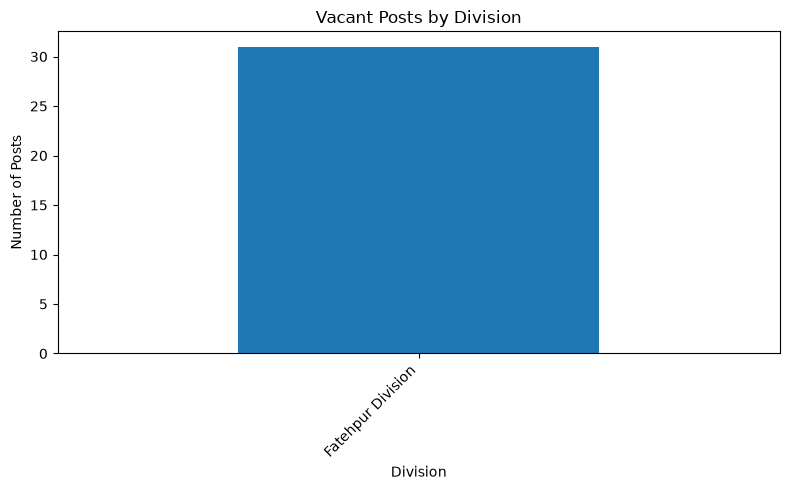

In [13]:
df["Division"].value_counts().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Vacant Posts by Division")
plt.xlabel("Division")
plt.ylabel("Number of Posts")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [14]:
print("Final dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Final dataset shape: (31, 6)

Missing values:
Sl. No.        0
Post Name      0
Post ID        0
Designation    0
Office Name    0
Division       0
dtype: int64

Total missing values: 0
Duplicate rows: 0


In [15]:
df.to_csv("cleaned_vacant_posts.csv", index=False)

print("Cleaned CSV saved successfully!")

Cleaned CSV saved successfully!


In [16]:
display(df.head(10))

,Sl. No.,Post Name,Post ID,Designation,Office Name,Division
0,1,Abhaipur BO-ABPM-UR,30357210,ABPM,Abhaipur BO,Fatehpur Division
1,2,Akbarpur Churai BO-BPM-UR,30350278,BPM,Akbarpur Churai BO,Fatehpur Division
2,3,Allipur BO-BPM-UR,30350327,BPM,Allipur BO,Fatehpur Division
3,4,Amilihapal BO-ABPM-OBC,30362623,ABPM,Amilihapal BO,Fatehpur Division
4,5,Andipur BO-ABPM-UR,30639378,ABPM,Andipur BO,Fatehpur Division
5,6,Arhawal BO-ABPM-OBC,30350633,ABPM,Arhawal BO,Fatehpur Division
6,7,Aung BO-ABPM-OBC,30357354,ABPM,Aung BO,Fatehpur Division
7,8,Baraipur BO-BPM-UR,30350484,BPM,Baraipur BO,Fatehpur Division
8,9,Bhakharana BO-BPM-OBC,30350295,BPM,Bhakharana BO,Fatehpur Division
9,10,Chandapur BO-BPM-UR,30357124,BPM,Chandapur BO,Fatehpur Division


In [17]:
# Check column names and missing values
print("Columns:", df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Remove completely empty columns, if any
df = df.dropna(axis=1, how="all")

print("\nDataset shape after cleaning:", df.shape)
print("\nRemaining missing values:")
print(df.isnull().sum())

Columns: ['Sl. No.', 'Post Name', 'Post ID', 'Designation', 'Office Name', 'Division']

Missing values:
Sl. No.        0
Post Name      0
Post ID        0
Designation    0
Office Name    0
Division       0
dtype: int64

Dataset shape after cleaning: (31, 6)

Remaining missing values:
Sl. No.        0
Post Name      0
Post ID        0
Designation    0
Office Name    0
Division       0
dtype: int64


In [18]:
# Analyze designation
print("Designation counts:")
print(df["Designation"].value_counts())

# Analyze office names
print("\nTop 10 offices:")
print(df["Office Name"].value_counts().head(10))

# Analyze divisions
print("\nDivision counts:")
print(df["Division"].value_counts())

Designation counts:
Designation
ABPM        18
BPM         12
Daksevak     1
Name: count, dtype: int64

Top 10 offices:
Office Name
Datauli BO            2
Abhaipur BO           1
Akbarpur Churai BO    1
Allipur BO            1
Amilihapal BO         1
Andipur BO            1
Arhawal BO            1
Aung BO               1
Baraipur BO           1
Bhakharana BO         1
Name: count, dtype: int64

Division counts:
Division
Fatehpur Division    31
Name: count, dtype: int64


In [19]:
print("Dataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all"))

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Sl. No.      31 non-null     int64
 1   Post Name    31 non-null     str  
 2   Post ID      31 non-null     int64
 3   Designation  31 non-null     str  
 4   Office Name  31 non-null     str  
 5   Division     31 non-null     str  
dtypes: int64(2), str(4)
memory usage: 1.6 KB

Statistical summary:


,Sl. No.,Post Name,Post ID,Designation,Office Name,Division
count,31.000000,31,3.100000e+01,31,31,31
unique,NaN,31,NaN,3,30,1
top,NaN,Abhaipur BO-ABPM-UR,NaN,ABPM,Datauli BO,Fatehpur Division
freq,NaN,1,NaN,18,2,31
mean,16.000000,NaN,3.293637e+07,NaN,NaN,NaN
std,9.092121,NaN,9.921115e+06,NaN,NaN,NaN
min,1.000000,NaN,3.035028e+07,NaN,NaN,NaN
25%,8.500000,NaN,3.035051e+07,NaN,NaN,NaN
50%,16.000000,NaN,3.035712e+07,NaN,NaN,NaN
75%,23.500000,NaN,3.035998e+07,NaN,NaN,NaN


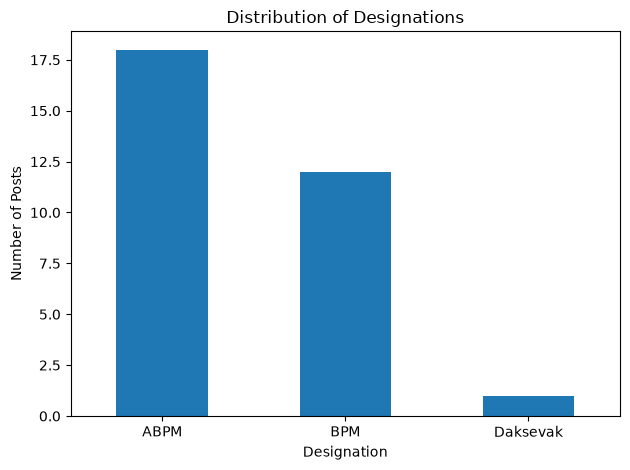

In [20]:
import matplotlib.pyplot as plt

df["Designation"].value_counts().plot(kind="bar")
plt.title("Distribution of Designations")
plt.xlabel("Designation")
plt.ylabel("Number of Posts")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

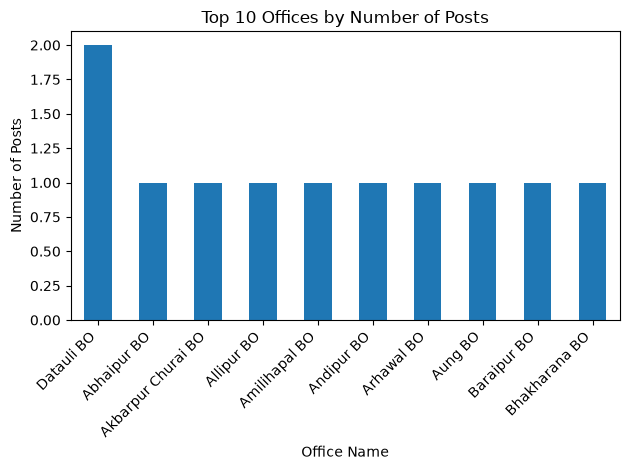

In [21]:
df["Office Name"].value_counts().head(10).plot(kind="bar")
plt.title("Top 10 Offices by Number of Posts")
plt.xlabel("Office Name")
plt.ylabel("Number of Posts")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

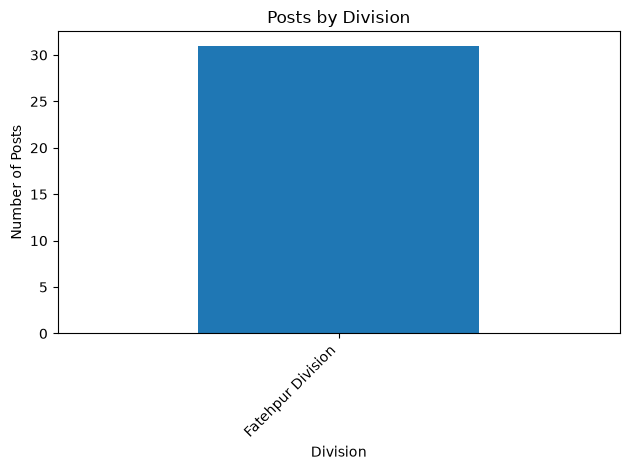

In [22]:
df["Division"].value_counts().plot(kind="bar")
plt.title("Posts by Division")
plt.xlabel("Division")
plt.ylabel("Number of Posts")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [23]:
df.to_csv("cleaned_vacant_posts.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Final dataset shape:", df.shape)

Cleaned dataset saved successfully!
Final dataset shape: (31, 6)
